# Analiza braków danych · 2026

Sprawdzimy, w których pytaniach i rekordach brakuje odpowiedzi, które braki pojawiają się razem i jak kompletność zmienia się między grupami respondentów. Rok w tytule oznacza edycję notatnika. Datę zbierania danych trzeba potwierdzić w dokumentacji ankiety.

Najpierw tworzymy binarną maskę braków. Za brak uznajemy puste pola, dokładny znacznik `NA` oraz pola złożone wyłącznie z białych znaków. Zachowujemy odpowiedzi tekstowe takie jak `None`. **pandas** wczytuje dane i buduje maskę, **NumPy** wspiera obliczenia, **SciPy** grupuje podobne pytania, a **Seaborn** i **Matplotlib** pokazują wyniki.

W JupyterLab wybierz kernel `python3` ze środowiska projektu i użyj **Run All**, aby przeliczyć wyniki.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "requirements.txt").is_file() and (path / "notebooks").is_dir()),
    None,
)
if root is None:
    raise RuntimeError("Uruchom notatnik z katalogu repozytorium lub notebooks/.")

data_dir = root / "data" / "raw"
responses_path = data_dir / "survey_results_public.csv"
with responses_path.open("rb") as source:
    if source.readline(256).startswith(b"version https://git-lfs.github.com/spec/"):
        raise RuntimeError("Pobierz pełny CSV poleceniem git lfs pull.")

responses = pd.read_csv(
    responses_path, keep_default_na=False, na_values=["", "NA"], low_memory=False,
)
schema = pd.read_csv(data_dir / "survey_results_schema.csv")
if responses.empty:
    raise ValueError("Plik odpowiedzi nie zawiera rekordów.")

missing = responses.isna()
for column in responses.select_dtypes(include=["object", "string"]):
    whitespace = responses[column].astype("string").str.fullmatch(r"\s*", na=False)
    missing[column] |= whitespace.to_numpy(dtype=bool)

sns.set_theme(style="whitegrid")
print(f"Rekordy: {len(responses):,} | Kolumny: {responses.shape[1]}")

Rekordy: 30,903 | Kolumny: 212


## 1. W których polach brakuje najwięcej odpowiedzi?

Dla każdego pola liczymy braki i dzielimy je przez liczbę wszystkich rekordów. Wykres pokazuje 20 pól z największym odsetkiem, a tabela obejmuje wszystkie pola. Wysoki odsetek wyznacza pytania do sprawdzenia w dokumentacji ankiety, szczególnie gdy były zadawane warunkowo.

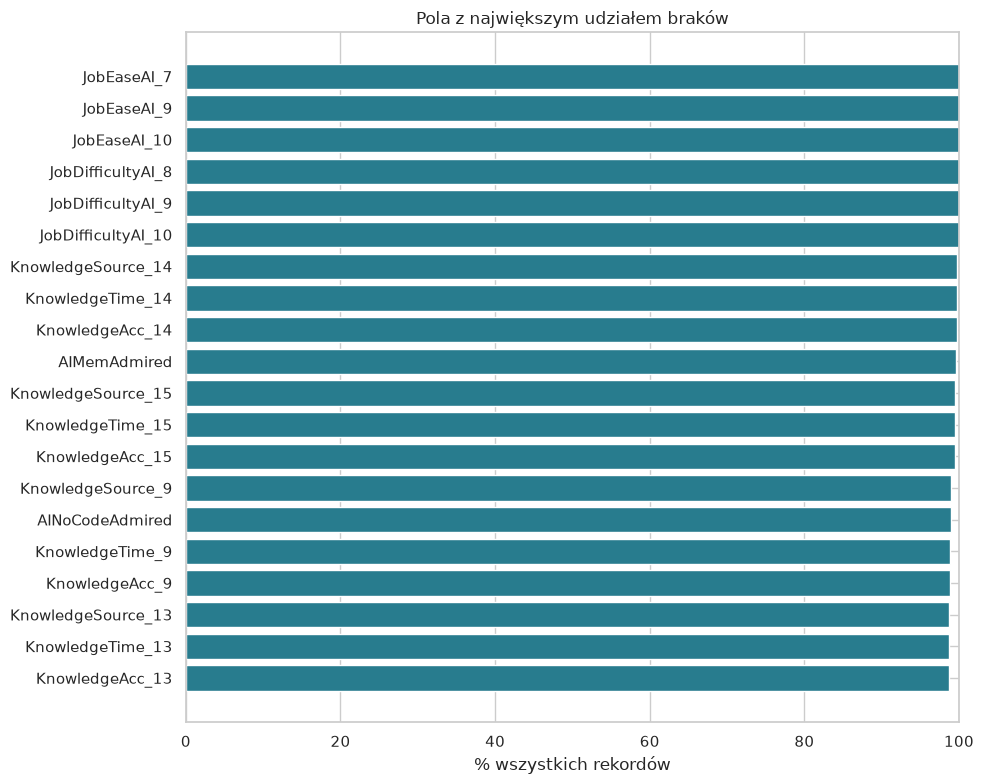

,braki,odpowiedzi,braki_%
JobEaseAI_7,30903,0,100.00
JobEaseAI_9,30903,0,100.00
JobEaseAI_10,30903,0,100.00
JobDifficultyAI_8,30903,0,100.00
JobDifficultyAI_9,30903,0,100.00
JobDifficultyAI_10,30903,0,100.00
KnowledgeSource_14,30814,89,99.71
KnowledgeTime_14,30810,93,99.70
KnowledgeAcc_14,30805,98,99.68
AIMemAdmired,30778,125,99.60


In [2]:
field_summary = pd.DataFrame({
    "braki": missing.sum(),
    "odpowiedzi": (~missing).sum(),
    "braki_%": missing.mean().mul(100),
}).sort_values("braki_%", ascending=False, kind="stable")

fig, ax = plt.subplots(figsize=(10, 8))
top_fields = field_summary.head(20).iloc[::-1]
ax.barh(top_fields.index, top_fields["braki_%"], color="#287c8e")
ax.set(xlim=(0, 100), xlabel="% wszystkich rekordów", title="Pola z największym udziałem braków")
plt.tight_layout()
plt.show()

with pd.option_context("display.max_rows", len(field_summary)):
    display(field_summary.round(2))

## 2. Czy liczba odpowiedzi zgadza się ze słownikiem danych?

Porównujemy własne liczniki z polem `nonmissing` w słowniku. Raportujemy osobno pola obecne tylko w jednym pliku i pola wspólne z rozbieżnymi licznikami. Różnica może wynikać m.in. z reguł liczenia białych znaków lub z wersji eksportu. Nie zmieniamy plików wejściowych.

In [3]:
schema_counts = pd.to_numeric(schema.set_index("column")["nonmissing"], errors="coerce")
observed = field_summary["odpowiedzi"]
only_data = observed.index.difference(schema_counts.index)
only_schema = schema_counts.index.difference(observed.index)
unchecked = schema_counts[schema_counts.isna()].index.intersection(observed.index)
comparison = pd.concat(
    [observed.rename("w CSV"), schema_counts.rename("w słowniku")], axis=1, join="inner",
).dropna()
comparison["różnica"] = comparison["w CSV"] - comparison["w słowniku"]
differences = comparison.loc[comparison["różnica"].ne(0)]
print(f"Tylko w CSV: {len(only_data)} {only_data.tolist()}")
print(f"Tylko w słowniku: {len(only_schema)} {only_schema.tolist()}")
print(f"Wspólne pola bez licznika w słowniku: {len(unchecked)} {unchecked.tolist()}")
print(f"Rozbieżne liczniki: {len(differences)} z {len(comparison)} porównanych pól")
display(differences.loc[differences["różnica"].abs().sort_values(ascending=False).index].head(20))

Tylko w CSV: 0 []
Tylko w słowniku: 0 []
Wspólne pola bez licznika w słowniku: 0 []
Rozbieżne liczniki: 0 z 212 porównanych pól


,w CSV,w słowniku,różnica


## 3. Ile braków przypada na jeden rekord?

Histogram pokazuje rozkład odsetka braków w rekordzie, a tabela podaje jego kwartyle i 90. percentyl. Dodatkowo liczymy najczęstsze identyczne wzorce obecności i braku odpowiedzi dla **wszystkich** pól. Pokazujemy tylko liczebności wzorców, bez odpowiedzi i identyfikatorów.

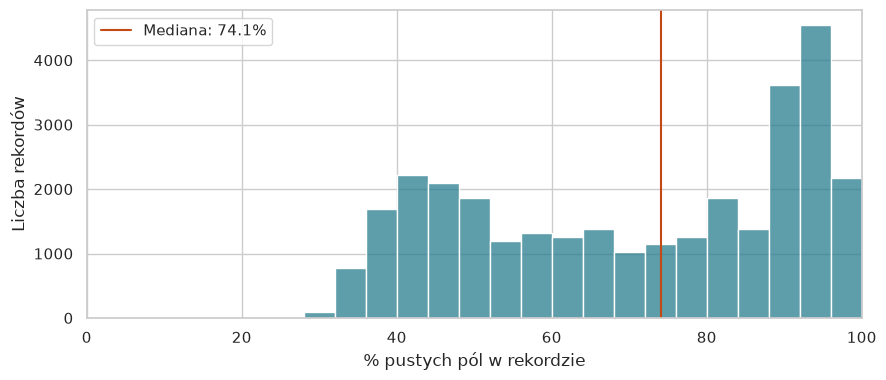

,braki_%
0.25,49.53
0.50,74.06
0.75,91.51
0.90,95.28


,liczba rekordów,odsetek rekordów,puste pola we wzorcu
pozycja,,,
1,994,3.22,207
2,561,1.82,203
3,541,1.75,202
4,443,1.43,194
5,435,1.41,193
6,406,1.31,201
7,285,0.92,194
8,268,0.87,195


In [4]:
row_rates = missing.mean(axis=1).mul(100)
packed = np.packbits(missing.to_numpy(dtype=bool), axis=1)
pattern_counts = pd.Series([row.tobytes() for row in packed], dtype=object).value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(row_rates, bins=np.linspace(0, 100, 26), color="#287c8e", ax=ax)
ax.axvline(row_rates.median(), color="#c24914", label=f"Mediana: {row_rates.median():.1f}%")
ax.set(xlim=(0, 100), xlabel="% pustych pól w rekordzie", ylabel="Liczba rekordów")
ax.legend()
plt.show()

display(row_rates.quantile([0.25, 0.5, 0.75, 0.9]).rename("braki_%").to_frame().round(2))
top_patterns = pattern_counts.head(8)
display(pd.DataFrame({
    "liczba rekordów": top_patterns.to_numpy(),
    "odsetek rekordów": (100 * top_patterns / len(responses)).round(2).to_numpy(),
    "puste pola we wzorcu": [sum(byte.bit_count() for byte in pattern) for pattern in top_patterns.index],
}, index=pd.RangeIndex(1, len(top_patterns) + 1, name="pozycja")))

## 4. Które pytania mają wspólne braki?

Na mapie pokazujemy korelację **phi**, czyli korelację Pearsona dwóch masek zero-jedynkowych. Wartości dodatnie oznaczają, że braki częściej występują razem, a ujemne wskazują przeciwne wzorce. Wybieramy do 24 pól o największej zmienności maski, czyli z udziałem braków najbliższym 50%. SciPy porządkuje pola według podobieństwa na podstawie odległości `1 − phi`. Wspólny wzorzec może podpowiadać, gdzie szukać wspólnego filtra ankiety.

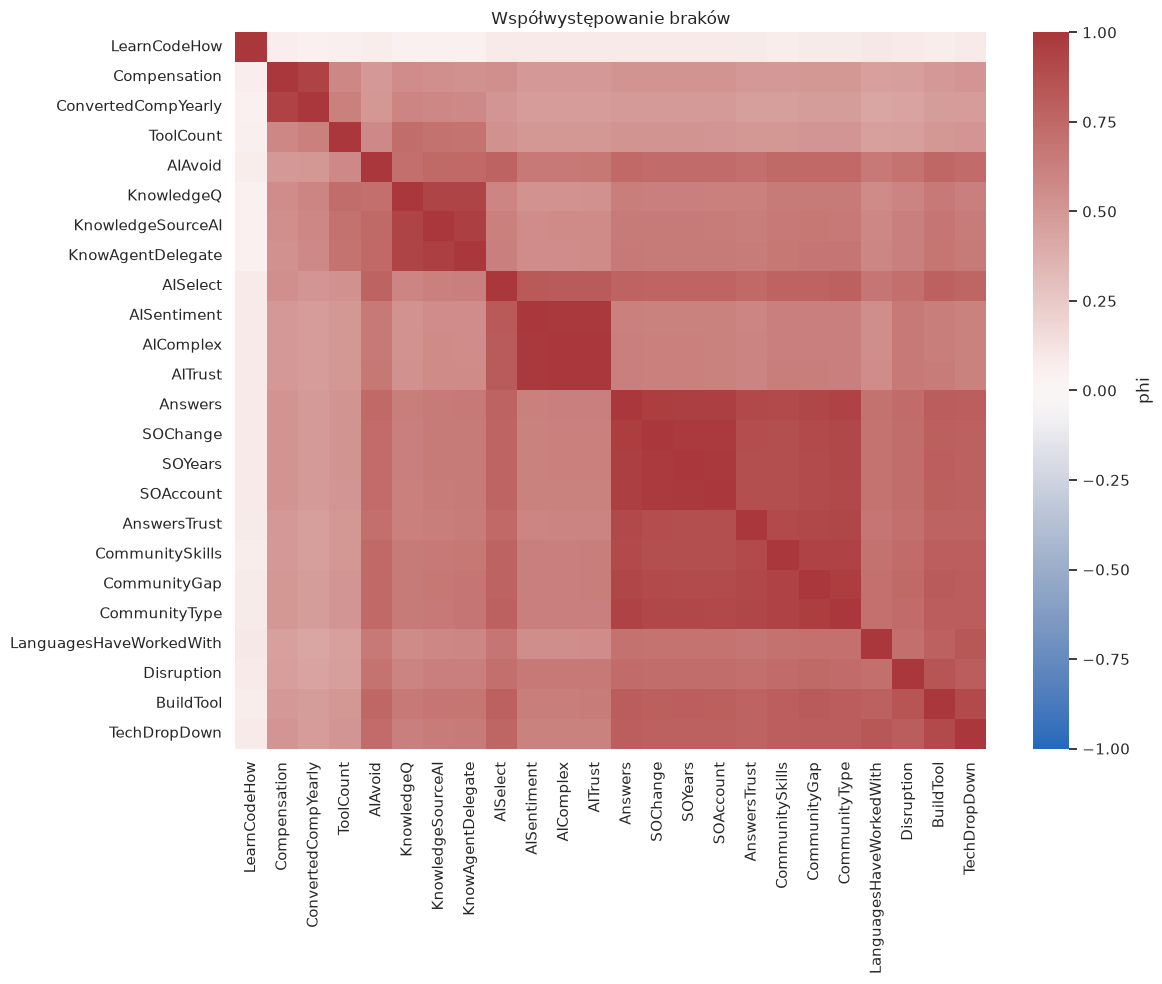

phi
AIComplex    AITrust        0.994
AISentiment  AIComplex      0.991
SOYears      SOAccount      0.989
AISentiment  AITrust        0.989
SOChange     SOYears        0.981
             SOAccount      0.979
CommunityGap CommunityType  0.965
Answers      SOChange       0.962

In [5]:
rates = missing.mean()
variable_rates = rates[rates.between(0, 1, inclusive="neither")]
selected = (variable_rates - 0.5).abs().nsmallest(24).index
if len(selected) >= 2:
    phi = missing[selected].astype(float).corr()
    distance = np.clip(1 - phi.to_numpy(), 0, 2)
    distance = (distance + distance.T) / 2
    np.fill_diagonal(distance, 0)
    order = leaves_list(linkage(squareform(distance), method="average"))
    ordered_phi = phi.iloc[order, order]

    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(ordered_phi, vmin=-1, vmax=1, center=0,
                cmap="vlag", cbar_kws={"label": "phi"}, ax=ax)
    ax.set_title("Współwystępowanie braków")
    plt.tight_layout()
    plt.show()

    upper = np.triu(np.ones(phi.shape, dtype=bool), k=1)
    pair_values = phi.where(upper).stack()
    display(pair_values.nlargest(8).rename("phi").to_frame().round(3))
else:
    print("Do porównania potrzeba co najmniej dwóch pól o zmiennym wzorcu braków.")

## 5. Jak odpowiedź na jedno pytanie wiąże się z kompletnością kolejnych?

Dla kategorii odpowiedzi na `AISelect` i `Employment` liczymy odsetek braków w powiązanych pytaniach. Pokazujemy grupy liczące co najmniej 100 rekordów, a podstawą każdego odsetka jest liczebność danej grupy. Osobno oznaczamy rekordy z brakiem w pytaniu grupującym. Wyniki mogą pomóc odnaleźć pytania warunkowe, których reguły trzeba sprawdzić w formularzu.

/tmp/ipykernel_3686/891789104.py:23: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


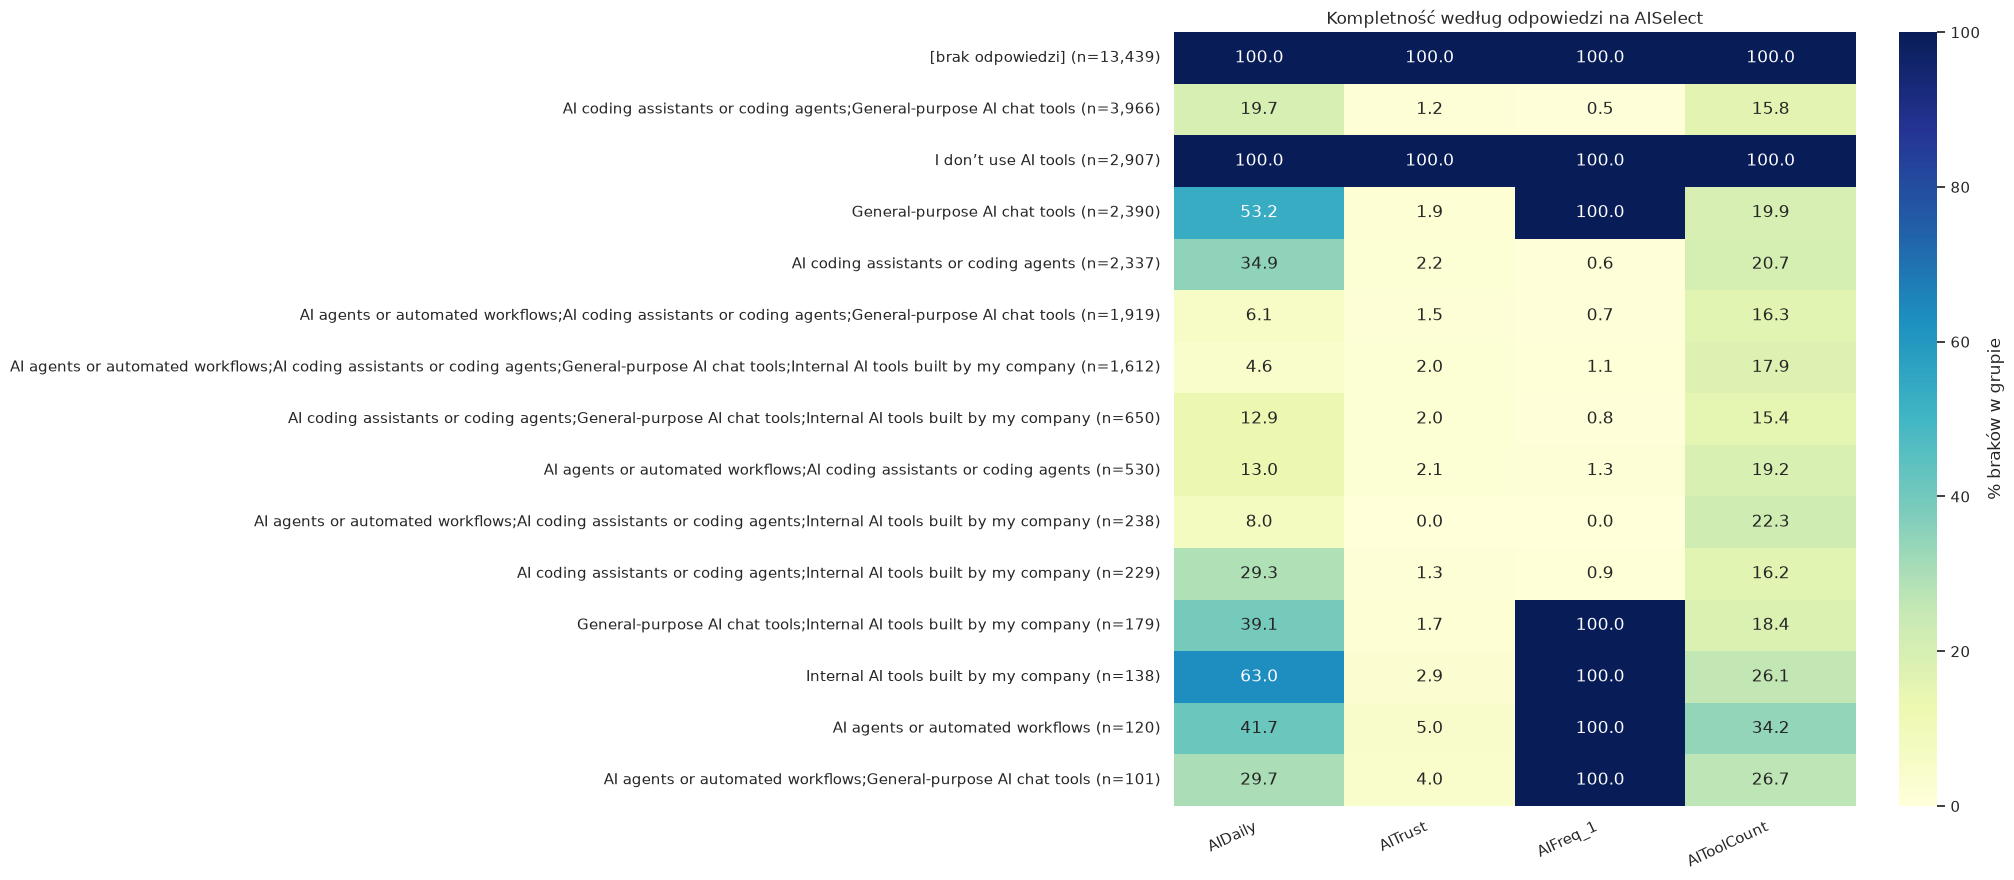

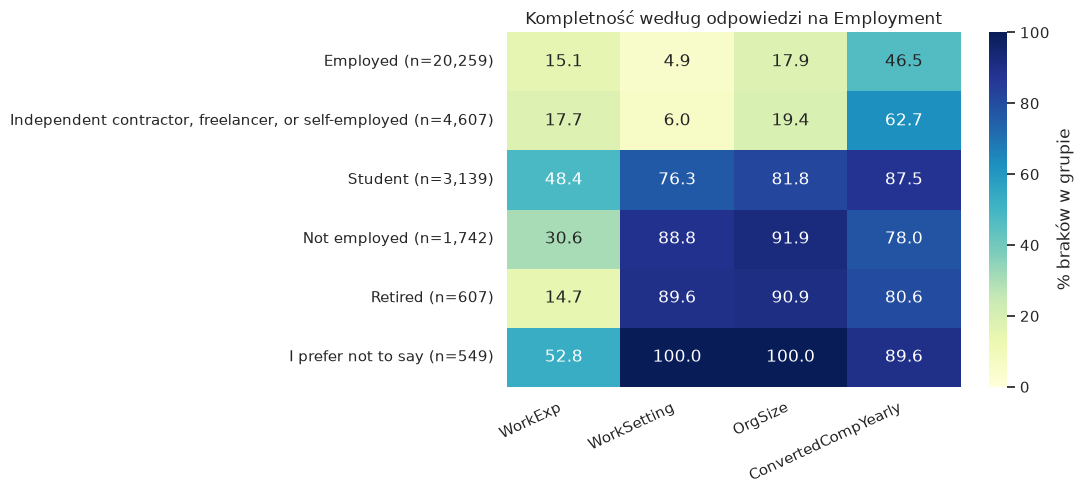

In [6]:
group_checks = {
    "AISelect": ["AIDaily", "AITrust", "AIFreq_1", "AIToolCount"],
    "Employment": ["WorkExp", "WorkSetting", "OrgSize", "ConvertedCompYearly"],
}
for group_field, outcomes in group_checks.items():
    outcomes = [field for field in outcomes if field in missing]
    if group_field not in responses or not outcomes:
        continue
    groups = responses[group_field].astype("string").mask(missing[group_field], "[brak odpowiedzi]")
    sizes = groups.value_counts()
    eligible = sizes[sizes.ge(100)]
    if eligible.empty:
        print(f"{group_field}: brak grup z co najmniej 100 rekordami.")
        continue

    group_rates = missing[outcomes].groupby(groups).mean().loc[eligible.index].mul(100)
    group_rates.index = [f"{label} (n={size:,})" for label, size in eligible.items()]
    fig, ax = plt.subplots(figsize=(11, max(2.5, 0.55 * len(group_rates) + 1.8)))
    sns.heatmap(group_rates, annot=True, fmt=".1f", vmin=0, vmax=100,
                cmap="YlGnBu", cbar_kws={"label": "% braków w grupie"}, ax=ax)
    ax.set(ylabel="", title=f"Kompletność według odpowiedzi na {group_field}")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 6. Co oznacza wysoki odsetek braków w konkretnym pytaniu?

Słownik opisuje `AIDaily` jako pytanie dla osób deklarujących codzienne użycie AI. Porównujemy odsetek braków w całym eksporcie z odsetkiem wśród osób, które wybrały `Daily` przynajmniej raz w polach `AIFreq_1`–`AIFreq_4`. To grupa zrekonstruowana z odpowiedzi. Bez logów formularza nie wiemy, komu faktycznie wyświetlono pytanie.

`JobEase` zawiera wybór jednego czynnika, a `JobEaseAI_1`–`JobEaseAI_10` przechowują odpowiedź uzupełniającą o roli AI dla poszczególnych czynników. Dla każdego podpunktu łączymy etykietę ze słownika z wyborem w `JobEase` i osobno liczymy zapisy w pasującej grupie oraz poza nią. Puste komórki poza pasującą grupą są zgodne ze strukturą pytania warunkowego. Brak zapisu w pasującej grupie wymaga sprawdzenia reguł formularza lub eksportu przed uznaniem go za pominiętą odpowiedź.


In [7]:
daily = responses[[f"AIFreq_{i}" for i in range(1, 5)]].eq("Daily").any(axis=1)
daily_bases = {
    "Cały eksport": missing["AIDaily"],
    "Co najmniej jedno Daily": missing.loc[daily, "AIDaily"],
    "Brak deklaracji Daily w AIFreq": missing.loc[~daily, "AIDaily"],
}
display(pd.DataFrame.from_dict({
    label: {"rekordy": len(mask), "odpowiedzi": int((~mask).sum()),
            "braki": int(mask.sum()), "braki_%": mask.mean() * 100}
    for label, mask in daily_bases.items()
}, orient="index").round(2))

raw_subquestion = pd.read_csv(
    responses_path, usecols=["JobEaseAI_7"], dtype=str, na_filter=False,
)["JobEaseAI_7"]
display(raw_subquestion.value_counts().rename("liczba rekordów").to_frame())
print("Odpowiedzi według słownika:", int(schema_counts.loc["JobEaseAI_7"]))
print("Wybory tej kategorii w JobEase:",
      int(responses["JobEase"].eq("Leadership activity or organizational changes").sum()))

job_ease_rows = []
for item in schema.loc[schema["column"].str.startswith("JobEaseAI_")].itertuples(index=False):
    selected_factor = responses["JobEase"].eq(item.sub).fillna(False)
    recorded = ~missing[item.column]
    job_ease_rows.append({
        "pole": item.column,
        "czynnik": item.sub,
        "wybrali czynnik": int(selected_factor.sum()),
        "zapis w pasującej grupie": int((selected_factor & recorded).sum()),
        "puste w pasującej grupie": int((selected_factor & ~recorded).sum()),
        "zapis poza grupą": int((~selected_factor & recorded).sum()),
    })
display(pd.DataFrame(job_ease_rows).set_index("pole"))
print("Maksymalna liczba zapisanych podpunktów na rekord:",
      int((~missing.filter(regex=r"^JobEaseAI_")).sum(axis=1).max()))


,rekordy,odpowiedzi,braki,braki_%
Cały eksport,30903,10926,19977,64.64
Co najmniej jedno Daily,10982,10926,56,0.51
Brak deklaracji Daily w AIFreq,19921,0,19921,100.00


,liczba rekordów
JobEaseAI_7,
NA,30903


Odpowiedzi według słownika: 0
Wybory tej kategorii w JobEase: 396


,czynnik,wybrali czynnik,zapis w pasującej grupie,puste w pasującej grupie,zapis poza grupą
pole,,,,,
JobEaseAI_1,Clear priorities or requirements,1314,1307,7,0
JobEaseAI_2,Access to the right tools or platforms,3714,3688,26,0
JobEaseAI_3,"Reliable systems, infrastructure, or environments",741,735,6,0
JobEaseAI_4,Helpful documentation or knowledge sharing,768,759,9,0
JobEaseAI_5,"Supportive teammates, managers, or mentors",3191,3164,27,0
JobEaseAI_6,"Enough time, staffing, or resources",1088,1078,10,0
JobEaseAI_7,Leadership activity or organizational changes,396,0,396,0
JobEaseAI_8,"Better processes, workflows, or coordination",1256,1242,14,0
JobEaseAI_9,Nothing has made my job easier in the past 6 m...,3902,0,3902,0


Maksymalna liczba zapisanych podpunktów na rekord: 1


## 7. Wnioski z bieżącego uruchomienia

Podsumowanie aktualizuje się po zmianie danych wejściowych. Udział braków opisuje cały eksport. Przy ocenie poszczególnych pytań warto najpierw ustalić, którzy respondenci mieli je zobaczyć, a potem przeliczyć kompletność dla tej grupy. Same wzorce braków nie pozwalają rozstrzygnąć, czy braki zależą od nieobserwowanych odpowiedzi.

In [8]:
most_missing = field_summary.index[0]
display(Markdown(
    f"- W eksporcie puste lub oznaczone jako brak jest **{missing.to_numpy().mean():.1%}** komórek. "
    f"Mediana udziału braków w rekordzie wynosi **{row_rates.median():.1f}%**.\n"
    f"- Do pól o największym udziale pustych komórek należy `{most_missing}` "
    f"(**{field_summary.loc[most_missing, 'braki_%']:.1f}%**). "
    f"Pól z co najmniej 90% braków jest **{field_summary['braki_%'].ge(90).sum()}**.\n"
    f"- W danych występuje **{len(pattern_counts):,}** różnych wzorców braków. "
    f"Najczęstszy obejmuje **{pattern_counts.iloc[0]:,}** rekordów.\n"
    f"- Liczniki CSV i słownika różnią się w **{len(differences)}** "
    f"z **{len(comparison)}** porównanych pól."
))

- W eksporcie puste lub oznaczone jako brak jest **70.6%** komórek. Mediana udziału braków w rekordzie wynosi **74.1%**.
- Do pól o największym udziale pustych komórek należy `JobEaseAI_7` (**100.0%**). Pól z co najmniej 90% braków jest **65**.
- W danych występuje **21,901** różnych wzorców braków. Najczęstszy obejmuje **994** rekordów.
- Liczniki CSV i słownika różnią się w **0** z **212** porównanych pól.